In [2]:
!pip install tensorflow scikit-learn matplotlib seaborn pandas

In [3]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf

from tensorflow.keras.datasets import imdb
from tensorflow.keras.preprocessing.sequence import pad_sequences
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Embedding, SimpleRNN, LSTM, GRU, Dense, Dropout

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)

# Load IMDB dataset
vocab_size = 10000
max_length = 200

(X_train, y_train), (X_test, y_test) = imdb.load_data(
    num_words=vocab_size
)

# Padding sequences
X_train = pad_sequences(X_train, maxlen=max_length)
X_test = pad_sequences(X_test, maxlen=max_length)

print("Training data shape:", X_train.shape)
print("Testing data shape:", X_test.shape)

17464789/17464789 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Training data shape: (25000, 200)
Testing data shape: (25000, 200)


In [4]:
def build_model(model_type):

    model = Sequential()

    model.add(Embedding(vocab_size, 64, input_length=max_length))

    if model_type == "RNN":
        model.add(SimpleRNN(64))

    elif model_type == "LSTM":
        model.add(LSTM(64))

    elif model_type == "GRU":
        model.add(GRU(64))

    model.add(Dropout(0.5))
    model.add(Dense(1, activation='sigmoid'))

    model.compile(
        optimizer='adam',
        loss='binary_crossentropy',
        metrics=['accuracy']
    )

    return model

In [5]:
models = {}
histories = {}

model_types = ["RNN", "LSTM", "GRU"]

for model_type in model_types:

    print("\nTraining", model_type, "Model")

    model = build_model(model_type)

    history = model.fit(
        X_train,
        y_train,
        epochs=5,
        batch_size=64,
        validation_split=0.2,
        verbose=1
    )

    models[model_type] = model
    histories[model_type] = history


Training RNN Model
Epoch 1/5


/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/embedding.py:100: UserWarning: Argument `input_length` is deprecated. Just remove it.
  warnings.warn(


313/313 ━━━━━━━━━━━━━━━━━━━━ 38s 113ms/step - accuracy: 0.6465 - loss: 0.6125 - val_accuracy: 0.7494 - val_loss: 0.5124
Epoch 2/5
313/313 ━━━━━━━━━━━━━━━━━━━━ 29s 75ms/step - accuracy: 0.8424 - loss: 0.3744 - val_accuracy: 0.7154 - val_loss: 0.5683
Epoch 3/5
313/313 ━━━━━━━━━━━━━━━━━━━━ 41s 74ms/step - accuracy: 0.8766 - loss: 0.3024 - val_accuracy: 0.7598 - val_loss: 0.5289
Epoch 4/5
313/313 ━━━━━━━━━━━━━━━━━━━━ 22s 72ms/step - accuracy: 0.9323 - loss: 0.1729 - val_accuracy: 0.7676 - val_loss: 0.5726
Epoch 5/5
313/313 ━━━━━━━━━━━━━━━━━━━━ 23s 72ms/step - accuracy: 0.9728 - loss: 0.0807 - val_accuracy: 0.7922 - val_loss: 0.6420

Training LSTM Model
Epoch 1/5
313/313 ━━━━━━━━━━━━━━━━━━━━ 52s 159ms/step - accuracy: 0.7699 - loss: 0.4760 - val_accuracy: 0.8612 - val_loss: 0.3311
Epoch 2/5
313/313 ━━━━━━━━━━━━━━━━━━━━ 83s 160ms/step - accuracy: 0.8977 - loss: 0.2656 - val_accuracy: 0.8684 - val_loss: 0.3308
Epoch 3/5
313/313 ━━━━━━━━━━━━━━━━━━━━ 52s 168ms/step - accuracy: 0.9247 - loss: 0.

In [6]:
results = []

for model_type, model in models.items():

    y_pred_prob = model.predict(X_test)
    y_pred = (y_pred_prob > 0.5).astype(int).flatten()

    accuracy = accuracy_score(y_test, y_pred)
    precision = precision_score(y_test, y_pred)
    recall = recall_score(y_test, y_pred)
    f1 = f1_score(y_test, y_pred)

    results.append({
        "Model": model_type,
        "Accuracy": accuracy,
        "Precision": precision,
        "Recall": recall,
        "F1 Score": f1
    })

    print("\n", model_type, "Classification Report")
    print(classification_report(y_test, y_pred))

results_df = pd.DataFrame(results)

print("\nModel Comparison:")
print(results_df)

782/782 ━━━━━━━━━━━━━━━━━━━━ 11s 13ms/step

 RNN Classification Report
              precision    recall  f1-score   support

           0       0.80      0.79      0.79     12500
           1       0.79      0.80      0.80     12500

    accuracy                           0.79     25000
   macro avg       0.79      0.79      0.79     25000
weighted avg       0.79      0.79      0.79     25000

782/782 ━━━━━━━━━━━━━━━━━━━━ 24s 30ms/step

 LSTM Classification Report
              precision    recall  f1-score   support

           0       0.87      0.84      0.85     12500
           1       0.84      0.88      0.86     12500

    accuracy                           0.86     25000
   macro avg       0.86      0.86      0.86     25000
weighted avg       0.86      0.86      0.86     25000

782/782 ━━━━━━━━━━━━━━━━━━━━ 22s 28ms/step

 GRU Classification Report
              precision    recall  f1-score   support

           0       0.83      0.89      0.86     12500
           1       0.88

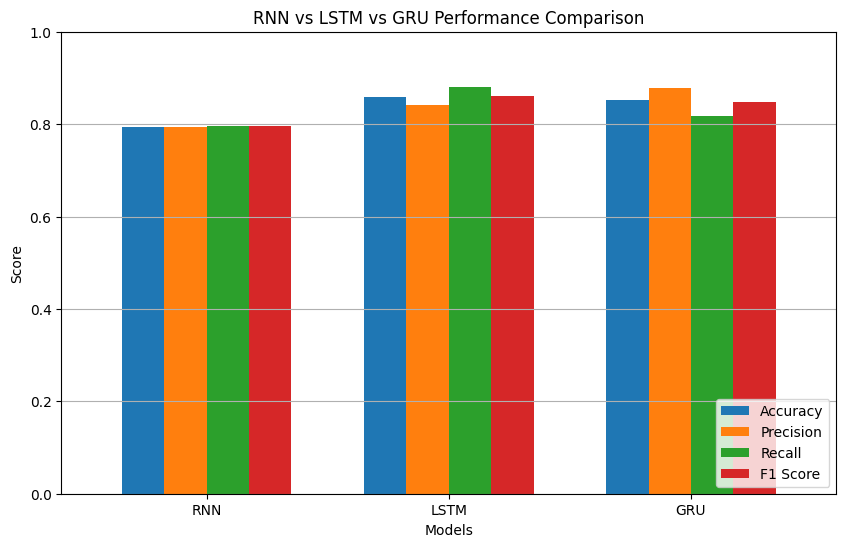

In [7]:
results_df.set_index("Model").plot(
    kind="bar",
    figsize=(10, 6),
    ylim=(0, 1),
    width=0.7
)

plt.title("RNN vs LSTM vs GRU Performance Comparison")
plt.ylabel("Score")
plt.xlabel("Models")
plt.xticks(rotation=0)
plt.legend(loc="lower right")
plt.grid(axis='y')
plt.show()

782/782 ━━━━━━━━━━━━━━━━━━━━ 10s 13ms/step


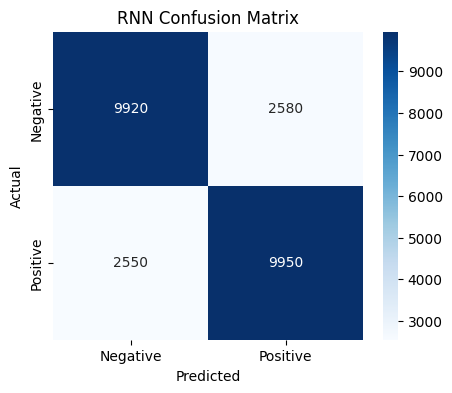

782/782 ━━━━━━━━━━━━━━━━━━━━ 22s 28ms/step


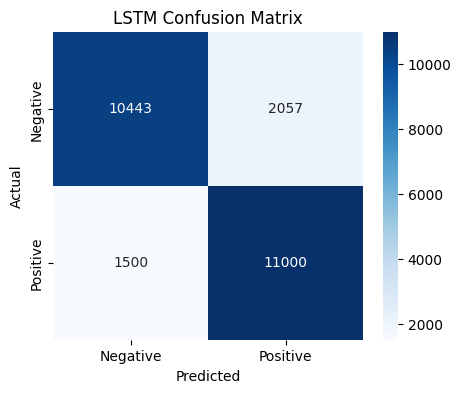

782/782 ━━━━━━━━━━━━━━━━━━━━ 22s 28ms/step


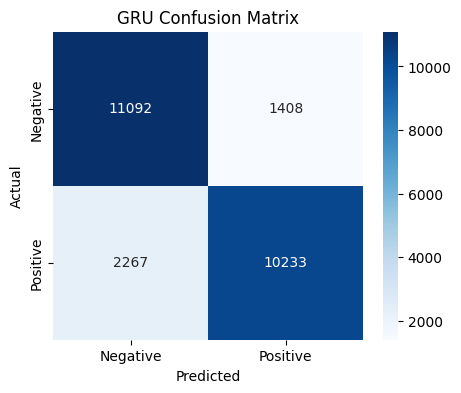

In [8]:
for model_type, model in models.items():

    y_pred = (model.predict(X_test) > 0.5).astype(int).flatten()

    cm = confusion_matrix(y_test, y_pred)

    plt.figure(figsize=(5, 4))

    sns.heatmap(
        cm,
        annot=True,
        fmt='d',
        cmap='Blues',
        xticklabels=['Negative', 'Positive'],
        yticklabels=['Negative', 'Positive']
    )

    plt.title(model_type + " Confusion Matrix")
    plt.xlabel("Predicted")
    plt.ylabel("Actual")
    plt.show()

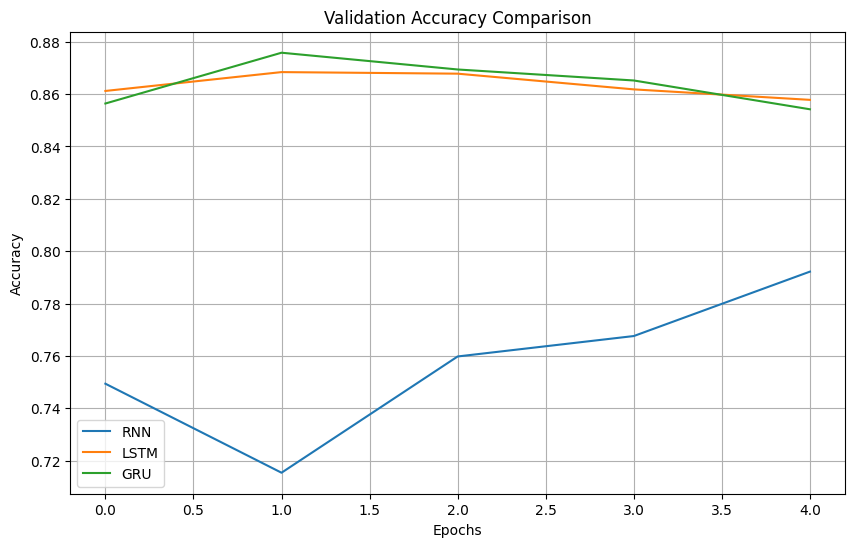

In [9]:
plt.figure(figsize=(10, 6))

for model_type, history in histories.items():

    plt.plot(
        history.history['val_accuracy'],
        label=model_type
    )

plt.title("Validation Accuracy Comparison")
plt.xlabel("Epochs")
plt.ylabel("Accuracy")
plt.legend()
plt.grid()
plt.show()

In [10]:
print("\nFINAL MODEL COMPARISON")

print(results_df.to_string(index=False))

best_model = results_df.loc[
    results_df['Accuracy'].idxmax()
]

print("\nBest Model:", best_model['Model'])
print("Best Accuracy:", best_model['Accuracy'])


FINAL MODEL COMPARISON
Model  Accuracy  Precision  Recall  F1 Score
  RNN   0.79480   0.794094 0.79600  0.795046
 LSTM   0.85772   0.842460 0.88000  0.860821
  GRU   0.85300   0.879048 0.81864  0.847769

Best Model: LSTM
Best Accuracy: 0.85772
